In [1]:
# ============================================================
# Cell 1 — Install and verify dependencies
# ============================================================
%pip install --quiet numpy pandas pyarrow requests yfinance python-dotenv matplotlib

import sys
from importlib.metadata import version

REQUIRED = ["numpy", "pandas", "pyarrow", "requests", "yfinance", "python-dotenv", "matplotlib"]

print(f"Python {sys.version.split()[0]}")
for package in REQUIRED:
    print(f"{package:<14} {version(package)}")

Note: you may need to restart the kernel to use updated packages.
Python 3.12.15
numpy          2.5.4
pandas         3.0.6
pyarrow        26.0.0
requests       2.34.2
yfinance       1.7.0
python-dotenv  1.2.4
matplotlib     3.11.2


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [1]:
# ============================================================
# Cell 2 — Project structure
# ============================================================
from pathlib import Path

PROJECT_ROOT = Path.cwd()
assert PROJECT_ROOT.name == "Cmmodities Factor Modeling", (
    f"Notebook is running from {PROJECT_ROOT}; open it from the project folder."
)

FOLDERS = [
    "src/commodity_factors/data",
    "data/raw",
    "data/processed",
    "reports/figures",
]

PACKAGE_INITS = {
    "src/commodity_factors/__init__.py": '"""Factor investing in US commodity futures."""\n',
    "src/commodity_factors/data/__init__.py": '"""Data acquisition and quality checks."""\n',
}

GITIGNORE = """\
# Environment and secrets
.env
__pycache__/
.ipynb_checkpoints/

# Data (re-downloadable; never commit raw vendor data)
data/raw/
data/processed/
"""

for folder in FOLDERS:
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)

for relative_path, content in PACKAGE_INITS.items():
    path = PROJECT_ROOT / relative_path
    if not path.exists():
        path.write_text(content, encoding="utf-8")

(PROJECT_ROOT / ".gitignore").write_text(GITIGNORE, encoding="utf-8")


def print_tree(root: Path, skip: tuple[str, ...] = (".ipynb_checkpoints", "__pycache__")) -> None:
    """Print the project tree, skipping cache folders."""
    for path in sorted(root.rglob("*")):
        if any(part in skip for part in path.parts):
            continue
        depth = len(path.relative_to(root).parts) - 1
        suffix = "/" if path.is_dir() else ""
        print(f"{'    ' * depth}{path.name}{suffix}")


print(f"Project root: {PROJECT_ROOT}\n")
print_tree(PROJECT_ROOT)

Project root: C:\Users\navon\OneDrive\Desktop\Cmmodities Factor Modeling

.gitignore
01_data_acquisition.ipynb
data/
    processed/
    raw/
reports/
    figures/
src/
    commodity_factors/
        __init__.py
        data/
            __init__.py


In [2]:
%%writefile src/commodity_factors/config.py
"""Project configuration: paths, contract universe and data-source settings."""

from __future__ import annotations

from collections.abc import Iterator
from dataclasses import dataclass
from enum import Enum
from pathlib import Path

import pandas as pd


# --------------------------------------------------------------------------- paths
@dataclass(frozen=True)
class ProjectPaths:
    """Filesystem layout, resolved from the repository root."""

    root: Path

    @property
    def raw(self) -> Path:
        return self.root / "data" / "raw"

    @property
    def processed(self) -> Path:
        return self.root / "data" / "processed"

    @property
    def figures(self) -> Path:
        return self.root / "reports" / "figures"


PATHS = ProjectPaths(root=Path(__file__).resolve().parents[2])


# ------------------------------------------------------------------------ universe
class Sector(str, Enum):
    ENERGY = "Energy"
    METALS = "Metals"
    GRAINS = "Grains"
    SOFTS = "Softs"
    LIVESTOCK = "Livestock"


@dataclass(frozen=True, slots=True)
class Commodity:
    """Static metadata for one futures contract."""

    symbol: str
    name: str
    sector: Sector
    exchange: str

    @property
    def yahoo_ticker(self) -> str:
        return f"{self.symbol}=F"


@dataclass(frozen=True)
class Universe:
    """Immutable, ordered collection of commodities with lookup helpers."""

    commodities: tuple[Commodity, ...]

    def __post_init__(self) -> None:
        symbols = [c.symbol for c in self.commodities]
        if len(symbols) != len(set(symbols)):
            raise ValueError("Universe contains duplicate symbols.")

    def __iter__(self) -> Iterator[Commodity]:
        return iter(self.commodities)

    def __len__(self) -> int:
        return len(self.commodities)

    @property
    def symbols(self) -> list[str]:
        return [c.symbol for c in self.commodities]

    @property
    def yahoo_tickers(self) -> list[str]:
        return [c.yahoo_ticker for c in self.commodities]

    @property
    def ticker_to_symbol(self) -> dict[str, str]:
        return {c.yahoo_ticker: c.symbol for c in self.commodities}

    @property
    def sector_map(self) -> dict[str, str]:
        return {c.symbol: c.sector.value for c in self.commodities}

    def by_sector(self, sector: Sector) -> Universe:
        return Universe(tuple(c for c in self.commodities if c.sector is sector))

    def to_frame(self) -> pd.DataFrame:
        return pd.DataFrame(
            [
                {
                    "name": c.name,
                    "sector": c.sector.value,
                    "exchange": c.exchange,
                    "yahoo_ticker": c.yahoo_ticker,
                }
                for c in self.commodities
            ],
            index=pd.Index(self.symbols, name="symbol"),
        )


UNIVERSE = Universe(
    (
        # Energy
        Commodity("CL", "WTI Crude Oil", Sector.ENERGY, "NYMEX"),
        Commodity("BZ", "Brent Crude Oil", Sector.ENERGY, "NYMEX"),
        Commodity("NG", "Henry Hub Natural Gas", Sector.ENERGY, "NYMEX"),
        Commodity("HO", "NY Harbor ULSD (Heating Oil)", Sector.ENERGY, "NYMEX"),
        Commodity("RB", "RBOB Gasoline", Sector.ENERGY, "NYMEX"),
        # Metals
        Commodity("GC", "Gold", Sector.METALS, "COMEX"),
        Commodity("SI", "Silver", Sector.METALS, "COMEX"),
        Commodity("HG", "Copper", Sector.METALS, "COMEX"),
        Commodity("PL", "Platinum", Sector.METALS, "NYMEX"),
        Commodity("PA", "Palladium", Sector.METALS, "NYMEX"),
        # Grains
        Commodity("ZC", "Corn", Sector.GRAINS, "CBOT"),
        Commodity("ZW", "Chicago SRW Wheat", Sector.GRAINS, "CBOT"),
        Commodity("KE", "KC HRW Wheat", Sector.GRAINS, "CBOT"),
        Commodity("ZS", "Soybeans", Sector.GRAINS, "CBOT"),
        Commodity("ZM", "Soybean Meal", Sector.GRAINS, "CBOT"),
        Commodity("ZL", "Soybean Oil", Sector.GRAINS, "CBOT"),
        Commodity("ZO", "Oats", Sector.GRAINS, "CBOT"),
        Commodity("ZR", "Rough Rice", Sector.GRAINS, "CBOT"),
        # Softs
        Commodity("KC", "Coffee", Sector.SOFTS, "ICE US"),
        Commodity("SB", "Sugar No. 11", Sector.SOFTS, "ICE US"),
        Commodity("CC", "Cocoa", Sector.SOFTS, "ICE US"),
        Commodity("CT", "Cotton", Sector.SOFTS, "ICE US"),
        Commodity("OJ", "Orange Juice", Sector.SOFTS, "ICE US"),
        # Livestock
        Commodity("LE", "Live Cattle", Sector.LIVESTOCK, "CME"),
        Commodity("HE", "Lean Hogs", Sector.LIVESTOCK, "CME"),
        Commodity("GF", "Feeder Cattle", Sector.LIVESTOCK, "CME"),
    )
)


# ---------------------------------------------------------------- EIA futures curves
@dataclass(frozen=True, slots=True)
class CurveSeries:
    """One maturity point on an EIA-published NYMEX futures curve."""

    symbol: str  # matches Commodity.symbol
    contract: int  # 1 = front month
    series_id: str  # EIA v1-style series id, served by the API v2 /seriesid route


def _curve(symbol: str, id_template: str, contracts: range) -> list[CurveSeries]:
    return [CurveSeries(symbol, n, id_template.format(n=n)) for n in contracts]


# EIA stopped publishing NYMEX futures prices after April 2024, so these histories end there.
# Heating oil has no contract 4 on EIA.
EIA_CURVES: tuple[CurveSeries, ...] = (
    *_curve("CL", "PET.RCLC{n}.D", range(1, 5)),
    *_curve("NG", "NG.RNGC{n}.D", range(1, 5)),
    *_curve("RB", "PET.EER_EPMRR_PE{n}_Y35NY_DPG.D", range(1, 5)),
    *_curve("HO", "PET.EER_EPD2F_PE{n}_Y35NY_DPG.D", range(1, 4)),
)

DEFAULT_START = "2000-01-01"

Writing src/commodity_factors/config.py


In [3]:
# ============================================================
# Cell 4 — Notebook setup and universe check
# ============================================================
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

SRC_DIR = Path.cwd() / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import pandas as pd

from commodity_factors.config import EIA_CURVES, PATHS, UNIVERSE, Sector

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

print(f"Project root : {PATHS.root}")
print(f"Raw data dir : {PATHS.raw}")
print(f"Contracts    : {len(UNIVERSE)}")
print(f"EIA series   : {len(EIA_CURVES)}\n")

print(UNIVERSE.to_frame().groupby("sector", sort=False).size().rename("n_contracts").to_string())

UNIVERSE.to_frame()

Project root : C:\Users\navon\OneDrive\Desktop\Cmmodities Factor Modeling
Raw data dir : C:\Users\navon\OneDrive\Desktop\Cmmodities Factor Modeling\data\raw
Contracts    : 26
EIA series   : 15

sector
Energy       5
Metals       5
Grains       8
Softs        5
Livestock    3


,name,sector,exchange,yahoo_ticker
symbol,,,,
CL,WTI Crude Oil,Energy,NYMEX,CL=F
BZ,Brent Crude Oil,Energy,NYMEX,BZ=F
NG,Henry Hub Natural Gas,Energy,NYMEX,NG=F
HO,NY Harbor ULSD (Heating Oil),Energy,NYMEX,HO=F
RB,RBOB Gasoline,Energy,NYMEX,RB=F
GC,Gold,Metals,COMEX,GC=F
SI,Silver,Metals,COMEX,SI=F
HG,Copper,Metals,COMEX,HG=F
PL,Platinum,Metals,NYMEX,PL=F


In [4]:
%%writefile src/commodity_factors/data/base.py
"""Base class for data sources that download once and cache to parquet."""

from __future__ import annotations

from abc import ABC, abstractmethod
from pathlib import Path
from typing import ClassVar

import pandas as pd


class CachedDataSource(ABC):
    """Template for a downloadable dataset with a local parquet cache.

    Subclasses implement ``fetch`` (network download) and set ``name``
    (cache file stem). ``load`` handles caching and index hygiene.
    """

    name: ClassVar[str]

    def __init__(self, cache_dir: Path) -> None:
        self._cache_dir = Path(cache_dir)

    @property
    def cache_path(self) -> Path:
        return self._cache_dir / f"{self.name}.parquet"

    def load(self, refresh: bool = False) -> pd.DataFrame:
        """Return cached data, downloading first if missing or ``refresh`` is True."""
        if self.cache_path.exists() and not refresh:
            return pd.read_parquet(self.cache_path)

        frame = self._standardise(self.fetch())
        self._cache_dir.mkdir(parents=True, exist_ok=True)
        frame.to_parquet(self.cache_path)
        return frame

    @abstractmethod
    def fetch(self) -> pd.DataFrame:
        """Download the dataset as a date-indexed DataFrame."""

    @staticmethod
    def _standardise(frame: pd.DataFrame) -> pd.DataFrame:
        if not isinstance(frame.index, pd.DatetimeIndex):
            raise TypeError("Fetched data must have a DatetimeIndex.")

        index = frame.index.tz_localize(None) if frame.index.tz is not None else frame.index
        frame = frame.set_axis(index.normalize().rename("date"), axis=0)
        frame = frame[~frame.index.duplicated(keep="last")].sort_index()
        return frame.dropna(how="all").astype("float64")

Writing src/commodity_factors/data/base.py


In [7]:
%%writefile src/commodity_factors/data/yahoo.py
"""Front-month continuous futures prices from Yahoo Finance."""

from __future__ import annotations

import warnings
from pathlib import Path

import pandas as pd
import yfinance as yf

from commodity_factors.config import DEFAULT_START, Universe
from commodity_factors.data.base import CachedDataSource


class YahooFuturesSource(CachedDataSource):
    """Daily front-month (``=F``) settlement prices for the whole universe.

    Yahoo stitches front-month contracts with no roll adjustment, so returns on
    roll days include the spread between contracts. Roll cleaning is handled
    downstream in the returns module, not here: this layer stores raw prices.
    """

    name = "yahoo_futures"

    def __init__(
        self,
        universe: Universe,
        cache_dir: Path,
        start: str = DEFAULT_START,
        end: str | None = None,
        field: str = "Close",
    ) -> None:
        super().__init__(cache_dir)
        self._universe = universe
        self._start = start
        self._end = end
        self._field = field

    def fetch(self) -> pd.DataFrame:
        raw = yf.download(
            tickers=self._universe.yahoo_tickers,
            start=self._start,
            end=self._end or pd.Timestamp.today().strftime("%Y-%m-%d"),  # exclude today's partial session
            auto_adjust=False,
            actions=False,
            progress=False,
            threads=True,
        )
        if raw is None or raw.empty:
            raise RuntimeError("Yahoo Finance returned no data. Check connection or rate limits.")

        prices = raw[self._field] if isinstance(raw.columns, pd.MultiIndex) else raw[[self._field]]
        prices = (
            prices.rename(columns=self._universe.ticker_to_symbol)
            .reindex(columns=self._universe.symbols)
            .rename_axis(columns="symbol")
        )

        missing = prices.columns[prices.isna().all()].tolist()
        if missing:
            warnings.warn(f"No Yahoo data for: {missing}", stacklevel=2)

        return prices

Overwriting src/commodity_factors/data/yahoo.py


In [8]:
# ============================================================
# Cell 7 — Download front-month prices (Yahoo Finance)
# ============================================================
from commodity_factors.data.yahoo import YahooFuturesSource

REFRESH = True  # set True to re-download and overwrite the cache

yahoo = YahooFuturesSource(UNIVERSE, cache_dir=PATHS.raw)
prices = yahoo.load(refresh=REFRESH)

print(f"Shape      : {prices.shape[0]:,} days x {prices.shape[1]} contracts")
print(f"Date range : {prices.index.min():%Y-%m-%d} -> {prices.index.max():%Y-%m-%d}")
print(f"Cached at  : {yahoo.cache_path}\n")

coverage = pd.DataFrame(
    {
        "first_date": prices.apply(lambda s: s.first_valid_index()),
        "last_date": prices.apply(lambda s: s.last_valid_index()),
        "n_obs": prices.notna().sum(),
    }
).join(UNIVERSE.to_frame()["sector"])

print(coverage.sort_values("first_date").to_string())

prices.tail()

Shape      : 6,755 days x 26 contracts
Date range : 2000-01-03 -> 2026-10-16
Cached at  : C:\Users\navon\OneDrive\Desktop\Cmmodities Factor Modeling\data\raw\yahoo_futures.parquet

       first_date  last_date  n_obs     sector
symbol                                        
KC     2000-01-03 2026-10-16   6717      Softs
CT     2000-01-03 2026-10-16   6719      Softs
ZO     2000-01-03 2026-10-16   6572     Grains
ZR     2000-01-03 2026-10-16   6724     Grains
CC     2000-01-03 2026-10-16   6719      Softs
PL     2000-01-04 2026-10-16   6041     Metals
PA     2000-01-04 2026-10-16   6280     Metals
SB     2000-03-01 2026-10-16   6680      Softs
ZL     2000-03-15 2026-10-16   6610     Grains
ZM     2000-05-15 2026-10-16   6572     Grains
ZC     2000-07-17 2026-10-16   6569     Grains
ZW     2000-07-17 2026-10-16   6581     Grains
CL     2000-08-23 2026-10-16   6566     Energy
HG     2000-08-30 2026-10-16   6562     Metals
GC     2000-08-30 2026-10-16   6558     Metals
NG     2000-08-30 20

symbol,CL,BZ,NG,HO,RB,GC,SI,HG,PL,PA,ZC,ZW,KE,ZS,ZM,ZL,ZO,ZR,KC,SB,CC,CT,OJ,LE,HE,GF
date,,,,,,,,,,,,,,,,,,,,,,,,,,
2026-10-12,93.739998,106.650002,3.167,4.7232,3.2917,4190.600098,60.140999,6.6985,1679.400024,1136.099976,483.00,672.25,715.25,1287.75,375.600006,68.300003,410.25,16.959999,290.600006,20.850000,5676.0,80.599998,151.399994,224.750000,75.599998,343.475006
2026-10-13,94.139999,105.690002,3.283,4.9344,3.2501,4177.299805,59.160999,6.6780,1657.400024,1117.900024,482.75,669.25,712.25,1283.75,370.100006,67.669998,415.50,17.209999,292.700012,21.110001,5733.0,80.510002,141.850006,224.625000,75.599998,343.075012
2026-10-14,95.089996,106.059998,3.198,4.9274,3.2595,4107.899902,55.549999,6.6115,1601.300049,1087.099976,480.75,673.25,715.00,1277.25,370.100006,67.050003,397.50,17.264999,298.049988,20.840000,5735.0,80.660004,142.449997,223.899994,75.550003,340.950012
2026-10-15,97.970001,105.919998,3.236,4.8456,3.1802,4170.100098,56.837002,6.5115,1610.699951,1121.000000,478.00,670.00,713.00,1263.00,359.799988,67.150002,396.00,17.254999,294.799988,21.129999,5831.0,80.059998,139.649994,225.949997,66.574997,343.375000
2026-10-16,101.410004,109.860001,3.116,4.8991,3.2354,4181.100098,56.994999,6.5310,1623.300049,1113.300049,474.25,660.50,704.00,1261.25,357.100006,67.129997,397.75,17.320000,305.600006,20.850000,5645.0,80.000000,141.399994,227.550003,66.925003,343.625000


In [9]:
%%writefile src/commodity_factors/data/quality.py
"""Data-quality diagnostics for wide, date-indexed price panels."""

from __future__ import annotations

from dataclasses import dataclass

import pandas as pd


@dataclass(frozen=True)
class QualityThresholds:
    max_abs_return: float = 0.20  # daily moves above this are flagged for review
    min_stale_run: int = 5  # consecutive identical prices treated as stale


class PriceQualityReport:
    """Coverage, gaps, stale prices and outlier moves for each price column."""

    def __init__(self, prices: pd.DataFrame, thresholds: QualityThresholds | None = None) -> None:
        self._prices = prices
        self._thresholds = thresholds or QualityThresholds()
        self._returns = prices.pct_change(fill_method=None)

    def summary(self) -> pd.DataFrame:
        """One row per column: coverage window, missing share, data problems."""
        records = [self._column_summary(self._prices[col]) for col in self._prices]
        return pd.DataFrame(records, index=self._prices.columns).convert_dtypes()

    def large_moves(self) -> pd.DataFrame:
        """Daily returns above the threshold, largest first (mostly roll gaps)."""
        moves = self._returns.melt(ignore_index=False, value_name="return").reset_index()
        flagged = moves[moves["return"].abs() > self._thresholds.max_abs_return]
        return flagged.sort_values("return", key=abs, ascending=False, ignore_index=True)

    def _column_summary(self, prices: pd.Series) -> dict:
        valid = prices.dropna()
        if valid.empty:
            return {"first_date": pd.NaT, "last_date": pd.NaT, "n_obs": 0}

        live = prices.loc[valid.index[0] : valid.index[-1]]
        returns = self._returns[prices.name].loc[live.index]
        return {
            "first_date": valid.index[0].date(),
            "last_date": valid.index[-1].date(),
            "n_obs": len(valid),
            "pct_missing": round(live.isna().mean() * 100, 2),
            "n_non_positive": int((valid <= 0).sum()),
            "n_large_moves": int((returns.abs() > self._thresholds.max_abs_return).sum()),
            **self._stale_runs(valid),
        }

    def _stale_runs(self, prices: pd.Series) -> dict:
        run_lengths = prices.ne(prices.shift()).cumsum().value_counts()
        return {
            "longest_stale_run": int(run_lengths.max()),
            "n_stale_runs": int((run_lengths >= self._thresholds.min_stale_run).sum()),
        }

Writing src/commodity_factors/data/quality.py


In [10]:
# ============================================================
# Cell 9 — Data-quality report: Yahoo front-month prices
# ============================================================
from commodity_factors.data.quality import PriceQualityReport

price_qc = PriceQualityReport(prices)

qc_summary = price_qc.summary().join(UNIVERSE.to_frame()["sector"])
print("Per-contract diagnostics")
print(qc_summary.drop(columns=["first_date", "last_date"]).to_string(), "\n")

large_moves = price_qc.large_moves()
print(f"Daily moves above 20%: {len(large_moves)} in total\n")

print("Count by contract")
print(large_moves["symbol"].value_counts().to_string(), "\n")

print("Top 25 largest moves")
print(large_moves.head(25).to_string())

Per-contract diagnostics
        n_obs  pct_missing  n_non_positive  n_large_moves  longest_stale_run  n_stale_runs     sector
symbol                                                                                               
CL       6566         0.41               1             11                  2             0     Energy
BZ       4784          1.1               0              3                  4             0     Energy
NG       6563         0.38               0             15                  2             0     Energy
HO       6560         0.39               0              1                  2             0     Energy
RB       6521         0.35               0             10                  2             0     Energy
GC       6558         0.46               0              0                  3             0     Metals
SI       6559         0.44               0              1                  3             0     Metals
HG       6562         0.39               0              1

In [11]:
# ============================================================
# Cell 10 — Drill into flagged data issues
# ============================================================
def missing_by_year(prices: pd.DataFrame, symbols: list[str]) -> pd.DataFrame:
    """Percentage of missing days per year, within each series' own lifetime."""
    by_year = {}
    for symbol in symbols:
        series = prices[symbol]
        live = series.loc[series.first_valid_index() : series.last_valid_index()]
        by_year[symbol] = live.isna().groupby(live.index.year).mean().mul(100).round(1)
    return pd.DataFrame(by_year).rename_axis("year")


def stale_runs(series: pd.Series, min_length: int = 5) -> pd.DataFrame:
    """Runs of identical consecutive prices at least ``min_length`` days long."""
    valid = series.dropna()
    run_id = valid.ne(valid.shift()).cumsum()
    dates = valid.index.to_series(index=valid.index)
    runs = pd.DataFrame(
        {
            "start": dates.groupby(run_id).first(),
            "end": dates.groupby(run_id).last(),
            "length": dates.groupby(run_id).size(),
            "price": valid.groupby(run_id).first(),
        }
    )
    return runs[runs["length"] >= min_length].reset_index(drop=True)


print("Missing days by year (%) — GC shown as a clean baseline")
print(missing_by_year(prices, ["PL", "PA", "ZO", "GC"]).to_string(), "\n")

for symbol in ["ZO", "LE", "HE", "KE"]:
    print(f"Stale runs (5+ identical prices): {symbol}")
    print(stale_runs(prices[symbol]).to_string(), "\n")

print("Oats: large moves by year")
print(large_moves.query("symbol == 'ZO'")["date"].dt.year.value_counts().sort_index().to_string())

Missing days by year (%) — GC shown as a clean baseline
        PL    PA    ZO   GC
year                       
2000   0.8   0.8  28.6  1.2
2001   1.6   2.0  36.1  2.0
2002  16.9   1.6   3.5  1.6
2003  14.3   0.8   0.4  0.8
2004  22.4   2.0   0.8  2.0
2005  16.1   7.1   0.4  2.4
2006  46.7  31.4   1.2  2.0
2007  49.4  58.9   0.8  0.4
2008  54.5  46.2   0.0  0.0
2009  57.5  28.6   0.0  0.0
2010   0.0   6.3   0.0  0.0
2011   0.0   0.0   0.0  0.0
2012   0.0   0.0   0.0  0.0
2013   0.0   0.0   0.0  0.0
2014   0.0   0.0   0.0  0.0
2015   0.0   0.0   0.0  0.0
2016   0.4   0.4   0.0  0.0
2017   0.0   0.0   0.0  0.0
2018   0.4   0.4   0.0  0.4
2019   0.0   0.0   0.0  0.0
2020   0.0   0.0   0.0  0.0
2021   0.0   0.0   0.0  0.0
2022   0.0   0.0   0.0  0.0
2023   0.4   0.4   0.4  0.0
2024   0.0   0.0   0.0  0.0
2025   0.0   0.4   0.4  0.0
2026   0.0   0.0   0.0  0.0 

Stale runs (5+ identical prices): ZO
       start        end  length   price
0 2001-09-17 2001-11-14      37  134.00
1 2001-12-17 

In [12]:
%%writefile -a src/commodity_factors/config.py


# ------------------------------------------------------------ data-quality rules
# First usable date per contract, set from the notebook 01 quality review.
# Earlier Yahoo data contains stale placeholder prices or heavy gaps.
DATA_START_OVERRIDES: dict[str, str] = {
    "ZO": "2004-01-01",  # repeated 134.00 placeholders, 28-36% missing days, 2000-2003
    "LE": "2005-06-01",  # recurring stale round-number prices, 2004-2005
    "PL": "2010-01-01",  # 15-58% missing days, 2002-2009
    "PA": "2010-01-01",  # 31-59% missing days, 2006-2009
}

STALE_RUN_MIN_LENGTH = 5  # runs of identical consecutive prices this long or longer are masked

Appending to src/commodity_factors/config.py


In [13]:
%%writefile src/commodity_factors/data/cleaning.py
"""Rule-based cleaning of raw price panels: start-date cut-offs and stale-run masking."""

from __future__ import annotations

from collections.abc import Mapping
from dataclasses import dataclass

import pandas as pd


@dataclass(frozen=True)
class CleaningResult:
    """Cleaned prices plus a per-contract audit log of what was removed."""

    prices: pd.DataFrame
    log: pd.DataFrame


class PriceCleaner:
    """Masks unusable data in a wide price panel without altering the raw input.

    Rules:
        1. Start-date overrides: drop observations before each contract's first usable date.
        2. Stale runs: mask runs of identical consecutive prices of ``stale_run_min_length``+ days.
    """

    def __init__(self, start_overrides: Mapping[str, str], stale_run_min_length: int) -> None:
        self._start_overrides = {symbol: pd.Timestamp(date) for symbol, date in start_overrides.items()}
        self._stale_run_min_length = stale_run_min_length

    def clean(self, prices: pd.DataFrame) -> CleaningResult:
        start_mask = self._start_date_mask(prices)
        stale_mask = prices.apply(self._stale_run_mask) & ~start_mask

        cleaned = prices.mask(start_mask | stale_mask).dropna(how="all")
        log = pd.DataFrame(
            {
                "obs_raw": prices.notna().sum(),
                "removed_pre_start": (start_mask & prices.notna()).sum(),
                "removed_stale": stale_mask.sum(),
                "obs_clean": cleaned.notna().sum(),
                "first_date_clean": cleaned.apply(lambda s: s.first_valid_index()),
            }
        )
        return CleaningResult(prices=cleaned, log=log)

    def _start_date_mask(self, prices: pd.DataFrame) -> pd.DataFrame:
        mask = pd.DataFrame(False, index=prices.index, columns=prices.columns)
        for symbol, start in self._start_overrides.items():
            if symbol in mask.columns:
                mask[symbol] = prices.index < start
        return mask

    def _stale_run_mask(self, series: pd.Series) -> pd.Series:
        valid = series.dropna()
        run_id = valid.ne(valid.shift()).cumsum()
        run_length = run_id.map(run_id.value_counts())
        is_stale = run_length >= self._stale_run_min_length
        return is_stale.reindex(series.index, fill_value=False)

Writing src/commodity_factors/data/cleaning.py


In [14]:
# ============================================================
# Cell 13 — Apply cleaning rules and re-check quality
# ============================================================
from commodity_factors.config import DATA_START_OVERRIDES, STALE_RUN_MIN_LENGTH
from commodity_factors.data.cleaning import PriceCleaner

cleaner = PriceCleaner(DATA_START_OVERRIDES, STALE_RUN_MIN_LENGTH)
result = cleaner.clean(prices)
prices_clean = result.prices

print("Cleaning audit log (contracts with changes)")
changed = result.log.query("removed_pre_start > 0 or removed_stale > 0")
print(changed.to_string(), "\n")

clean_qc = PriceQualityReport(prices_clean)
clean_summary = clean_qc.summary()
clean_moves = clean_qc.large_moves()

print("Before vs after cleaning")
print(f"  Large moves (>20%) : {len(large_moves)} -> {len(clean_moves)}")
print(f"  Stale runs (5+)    : {qc_summary['n_stale_runs'].sum()} -> {clean_summary['n_stale_runs'].sum()}\n")

print("Remaining large moves by contract")
print(clean_moves["symbol"].value_counts().to_string(), "\n")

PATHS.processed.mkdir(parents=True, exist_ok=True)
prices_clean.to_parquet(PATHS.processed / "prices_clean.parquet")
result.log.to_csv(PATHS.processed / "cleaning_log.csv")
print(f"Saved: {PATHS.processed / 'prices_clean.parquet'}")

Cleaning audit log (contracts with changes)
        obs_raw  removed_pre_start  removed_stale  obs_clean first_date_clean
symbol                                                                       
PL         6041               1820              0       4221       2010-01-04
PA         6280               2076              0       4204       2010-01-04
KE         6558                  0              6       6552       2000-09-21
ZO         6572                837              5       5730       2004-01-02
LE         6424               1068              0       5356       2005-06-01
HE         6492                  0              7       6485       2000-12-15 

Before vs after cleaning
  Large moves (>20%) : 72 -> 63
  Stale runs (5+)    : 16 -> 0

Remaining large moves by contract
symbol
NG    15
CL    11
RB    10
HE     6
ZR     3
BZ     3
ZO     2
PA     2
ZS     2
SI     1
SB     1
CT     1
ZC     1
CC     1
HG     1
HO     1
OJ     1
ZW     1 

Saved: C:\Users\navon\OneDrive\Deskt

In [15]:
%%writefile src/commodity_factors/data/eia.py
"""NYMEX energy futures curves (contracts 1-4) from the EIA API v2."""

from __future__ import annotations

import warnings
from collections.abc import Sequence
from pathlib import Path

import pandas as pd
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

from commodity_factors.config import CurveSeries
from commodity_factors.data.base import CachedDataSource


def build_session(retries: int = 3, backoff: float = 1.0) -> requests.Session:
    """HTTP session with retry/backoff on transient errors and rate limits."""
    retry = Retry(
        total=retries,
        backoff_factor=backoff,
        status_forcelist=(429, 500, 502, 503, 504),
        allowed_methods=("GET",),
    )
    session = requests.Session()
    session.mount("https://", HTTPAdapter(max_retries=retry))
    return session


class EIACurveSource(CachedDataSource):
    """Daily NYMEX futures prices by contract number, as published by EIA.

    Output columns are a MultiIndex of (symbol, contract), e.g. ("CL", 1).
    EIA stopped publishing these series after April 2024.
    """

    name = "eia_curves"
    URL = "https://api.eia.gov/v2/seriesid/{series_id}"
    PAGE_SIZE = 5000

    def __init__(
        self,
        curves: Sequence[CurveSeries],
        cache_dir: Path,
        api_key: str | None,
        timeout: float = 30.0,
    ) -> None:
        super().__init__(cache_dir)
        self._curves = tuple(curves)
        self._api_key = api_key
        self._timeout = timeout
        self._session = build_session()

    def fetch(self) -> pd.DataFrame:
        if not self._api_key:
            raise ValueError(
                "EIA_API_KEY is not set. Register for a free key at "
                "https://www.eia.gov/opendata/register.php and add it to .env"
            )

        series = {(c.symbol, c.contract): self._fetch_series(c.series_id) for c in self._curves}
        frame = pd.concat(series, axis=1)
        frame.columns = frame.columns.set_names(["symbol", "contract"])
        return frame.sort_index(axis=1)

    def _fetch_series(self, series_id: str) -> pd.Series:
        rows: list[dict] = []
        offset = 0
        while True:
            payload = self._get_page(series_id, offset)
            page = payload.get("data", [])
            rows.extend(page)
            offset += len(page)
            total = int(payload.get("total") or 0)
            if len(page) < self.PAGE_SIZE or (total and offset >= total):
                break

        if not rows:
            warnings.warn(f"EIA returned no rows for {series_id}; verify the id.", stacklevel=2)
            return pd.Series(dtype="float64", index=pd.DatetimeIndex([]), name=series_id)

        data = pd.DataFrame(rows)
        return pd.Series(
            pd.to_numeric(data["value"], errors="coerce").to_numpy(),
            index=pd.DatetimeIndex(pd.to_datetime(data["period"])),
            name=series_id,
        ).sort_index()

    def _get_page(self, series_id: str, offset: int) -> dict:
        response = self._session.get(
            self.URL.format(series_id=series_id),
            params={"api_key": self._api_key, "offset": offset, "length": self.PAGE_SIZE},
            timeout=self._timeout,
        )
        response.raise_for_status()
        return response.json()["response"]

Writing src/commodity_factors/data/eia.py


In [16]:
# ============================================================
# Cell 15 — EIA API key and energy curve download
# ============================================================
import os
from getpass import getpass

from dotenv import load_dotenv, set_key

from commodity_factors.data.eia import EIACurveSource

ENV_PATH = PATHS.root / ".env"
load_dotenv(ENV_PATH)

if not os.getenv("EIA_API_KEY"):
    api_key = getpass("Paste your EIA API key and press Enter: ").strip()
    ENV_PATH.touch(exist_ok=True)
    set_key(str(ENV_PATH), "EIA_API_KEY", api_key)
    os.environ["EIA_API_KEY"] = api_key
    print("API key saved to .env (git-ignored)\n")

eia = EIACurveSource(EIA_CURVES, cache_dir=PATHS.raw, api_key=os.getenv("EIA_API_KEY"))
curves = eia.load(refresh=False)

print(f"Shape      : {curves.shape[0]:,} days x {curves.shape[1]} series")
print(f"Date range : {curves.index.min():%Y-%m-%d} -> {curves.index.max():%Y-%m-%d}")
print(f"Cached at  : {eia.cache_path}\n")

curve_qc = PriceQualityReport(curves)
print("Per-series diagnostics")
print(curve_qc.summary().to_string(), "\n")

print("Last 3 rows")
print(curves.tail(3).round(3).to_string())

Paste your EIA API key and press Enter:  ········


API key saved to .env (git-ignored)

Shape      : 11,127 days x 15 series
Date range : 1980-01-02 -> 2024-04-05
Cached at  : C:\Users\navon\OneDrive\Desktop\Cmmodities Factor Modeling\data\raw\eia_curves.parquet

Per-series diagnostics
                 first_date   last_date  n_obs  pct_missing  n_non_positive  n_large_moves  longest_stale_run  n_stale_runs
symbol contract                                                                                                            
CL     1         1983-04-04  2024-04-05  10305         0.05               1             12                  2             0
       2         1985-01-02  2024-04-05   9868         0.03               0              6                  2             0
       3         1983-03-30  2024-04-05  10309         0.03               0              6                  3             0
       4         1985-01-02  2024-04-05   9868         0.03               0              4                  3             0
HO     1         198

Annualised carry since 2000 (positive = backwardation)
     mean  median  pct_backwardated    min    max
CL -0.045  -0.038            36.748 -4.877  1.205
HO  0.008  -0.028            36.371 -1.720  2.974
NG -0.276  -0.165            17.899 -4.679  4.564
RB  0.028   0.045            46.222 -2.900  2.217


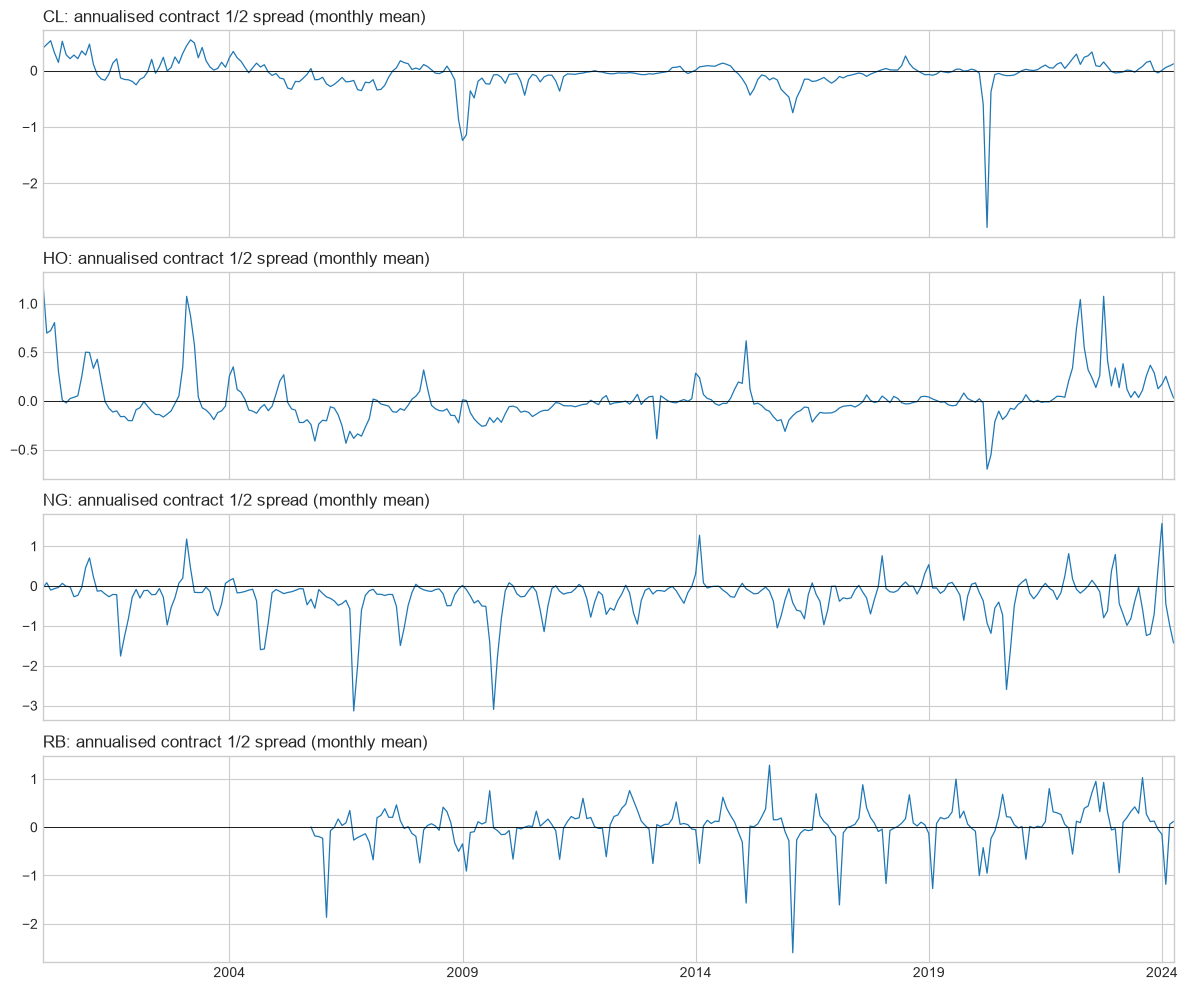

In [17]:
# ============================================================
# Cell 16 — Carry preview: annualised front/next spread (2000+)
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

plt.style.use("seaborn-v0_8-whitegrid")
PATHS.figures.mkdir(parents=True, exist_ok=True)

energy_symbols = curves.columns.get_level_values("symbol").unique().tolist()

# Monthly-listed contracts: log(F1/F2) x 12 approximates annualised carry
carry_preview = pd.DataFrame(
    {symbol: np.log(curves[(symbol, 1)] / curves[(symbol, 2)]) * 12 for symbol in energy_symbols}
).loc["2000":]

carry_stats = pd.DataFrame(
    {
        "mean": carry_preview.mean(),
        "median": carry_preview.median(),
        "pct_backwardated": carry_preview.gt(0).mean().mul(100),
        "min": carry_preview.min(),
        "max": carry_preview.max(),
    }
).round(3)
print("Annualised carry since 2000 (positive = backwardation)")
print(carry_stats.to_string())

fig, axes = plt.subplots(len(energy_symbols), 1, figsize=(12, 10), sharex=True)
for ax, symbol in zip(axes, energy_symbols):
    carry_preview[symbol].resample("ME").mean().plot(ax=ax, lw=0.9)
    ax.axhline(0, color="black", lw=0.6)
    ax.set_title(f"{symbol}: annualised contract 1/2 spread (monthly mean)", loc="left")
    ax.set_xlabel("")

fig.tight_layout()
fig.savefig(PATHS.figures / "01_energy_carry_preview.png", dpi=150)
plt.show()

In [18]:
# ============================================================
# Cell 17 — Notebook 01 summary
# ============================================================
def list_outputs(folder: Path) -> pd.DataFrame:
    """Files in a folder with their sizes, ignoring hidden files."""
    files = [p for p in sorted(folder.iterdir()) if p.is_file() and not p.name.startswith(".")]
    return pd.DataFrame(
        {"file": [p.name for p in files], "size_kb": [round(p.stat().st_size / 1024, 1) for p in files]}
    )


for label, folder in {
    "Raw data": PATHS.raw,
    "Processed data": PATHS.processed,
    "Figures": PATHS.figures,
}.items():
    print(f"{label} ({folder.relative_to(PATHS.root)})")
    print(list_outputs(folder).to_string(index=False), "\n")

print("Datasets")
print(
    f"  Front-month prices (clean) : {prices_clean.shape[1]} contracts, "
    f"{prices_clean.index.min():%Y-%m-%d} -> {prices_clean.index.max():%Y-%m-%d}"
)
print(
    f"  Energy curves (EIA)        : {curves.shape[1]} series, "
    f"{curves.index.min():%Y-%m-%d} -> {curves.index.max():%Y-%m-%d}"
)

Raw data (data\raw)
                 file  size_kb
   eia_curves.parquet    518.2
yahoo_futures.parquet    825.1 

Processed data (data\processed)
                file  size_kb
    cleaning_log.csv      0.8
prices_clean.parquet    796.8 

Figures (reports\figures)
                       file  size_kb
01_energy_carry_preview.png    228.4 

Datasets
  Front-month prices (clean) : 26 contracts, 2000-01-03 -> 2026-10-16
  Energy curves (EIA)        : 15 series, 1980-01-02 -> 2024-04-05
